# **Import Libraries**

In [25]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.impute import SimpleImputer

from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)

from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import shap
import joblib

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


# **Load and Explore Dataset**

In [ ]:
file_path = "D:\AI_Projects\small projects\DATASET\IPL DATASET.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

Dataset loaded successfully.
Dataset shape: (76014, 15)


In [27]:
df.head(10)

,mid,date,venue,batting_team,bowling_team,batsman,bowler,runs,wickets,overs,runs_last_5,wickets_last_5,striker,non-striker,total
0,1,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,SC Ganguly,P Kumar,1,0,0.1,1,0,0,0,222
1,1,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,P Kumar,1,0,0.2,1,0,0,0,222
2,1,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,P Kumar,2,0,0.2,2,0,0,0,222
3,1,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,P Kumar,2,0,0.3,2,0,0,0,222
4,1,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,P Kumar,2,0,0.4,2,0,0,0,222
5,1,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,P Kumar,2,0,0.5,2,0,0,0,222
6,1,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,P Kumar,3,0,0.6,3,0,0,0,222
7,1,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,Z Khan,3,0,1.1,3,0,0,0,222
8,1,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,Z Khan,7,0,1.2,7,0,4,0,222
9,1,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,Z Khan,11,0,1.3,11,0,8,0,222


In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76014 entries, 0 to 76013
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   mid             76014 non-null  int64  
 1   date            76014 non-null  object 
 2   venue           76014 non-null  object 
 3   batting_team    76014 non-null  object 
 4   bowling_team    76014 non-null  object 
 5   batsman         76014 non-null  object 
 6   bowler          76014 non-null  object 
 7   runs            76014 non-null  int64  
 8   wickets         76014 non-null  int64  
 9   overs           76014 non-null  float64
 10  runs_last_5     76014 non-null  int64  
 11  wickets_last_5  76014 non-null  int64  
 12  striker         76014 non-null  int64  
 13  non-striker     76014 non-null  int64  
 14  total           76014 non-null  int64  
dtypes: float64(1), int64(8), object(6)
memory usage: 8.7+ MB


In [29]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
mid,76014.0,NaN,NaN,NaN,308.62774,178.156878,1.0,154.0,308.0,463.0,617.0
date,76014,442,2010-03-25,257,NaN,NaN,NaN,NaN,NaN,NaN,NaN
venue,76014,35,M Chinnaswamy Stadium,7443,NaN,NaN,NaN,NaN,NaN,NaN,NaN
batting_team,76014,14,Mumbai Indians,10213,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bowling_team,76014,14,Delhi Daredevils,10245,NaN,NaN,NaN,NaN,NaN,NaN,NaN
batsman,76014,411,SK Raina,1921,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bowler,76014,329,Harbhajan Singh,1404,NaN,NaN,NaN,NaN,NaN,NaN,NaN
runs,76014.0,NaN,NaN,NaN,74.889349,48.823327,0.0,34.0,70.0,111.0,263.0
wickets,76014.0,NaN,NaN,NaN,2.415844,2.015207,0.0,1.0,2.0,4.0,10.0
overs,76014.0,NaN,NaN,NaN,9.783068,5.772587,0.0,4.6,9.6,14.6,19.6


In [30]:
missing_values = pd.DataFrame({
    "Column": df.columns,
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df) * 100
    )
})

missing_values = missing_values.sort_values(
    by="Missing Values",
    ascending=False
)

missing_values

,Column,Missing Values,Missing Percentage
mid,mid,0,0.0
date,date,0,0.0
venue,venue,0,0.0
batting_team,batting_team,0,0.0
bowling_team,bowling_team,0,0.0
batsman,batsman,0,0.0
bowler,bowler,0,0.0
runs,runs,0,0.0
wickets,wickets,0,0.0
overs,overs,0,0.0


In [31]:
print(
    "Number of duplicate rows:",
    df.duplicated().sum()
)

Number of duplicate rows: 0


In [32]:
for column in df.columns:
    print(
        f"{column}: "
        f"{df[column].nunique()} unique values"
    )

mid: 617 unique values
date: 442 unique values
venue: 35 unique values
batting_team: 14 unique values
bowling_team: 14 unique values
batsman: 411 unique values
bowler: 329 unique values
runs: 252 unique values
wickets: 11 unique values
overs: 140 unique values
runs_last_5: 102 unique values
wickets_last_5: 8 unique values
striker: 155 unique values
non-striker: 88 unique values
total: 138 unique values


# **Exploratory Data Analysis**

In [33]:
print("Target variable: total")

print("\nTarget statistics:")
print(df["total"].describe())

Target variable: total

Target statistics:
count    76014.000000
mean       160.901452
std         29.246231
min         67.000000
25%        142.000000
50%        162.000000
75%        181.000000
max        263.000000
Name: total, dtype: float64


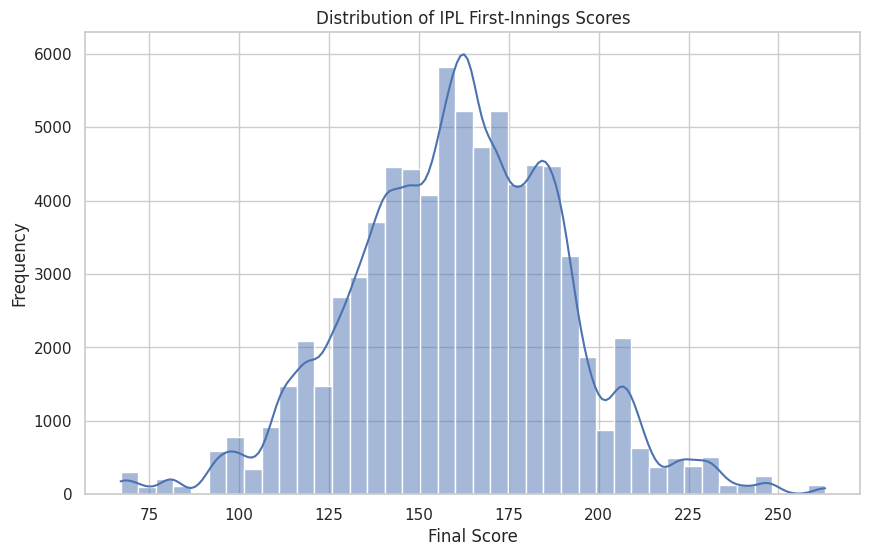

In [34]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="total",
    bins=40,
    kde=True
)

plt.title("Distribution of IPL First-Innings Scores")
plt.xlabel("Final Score")
plt.ylabel("Frequency")

plt.show()

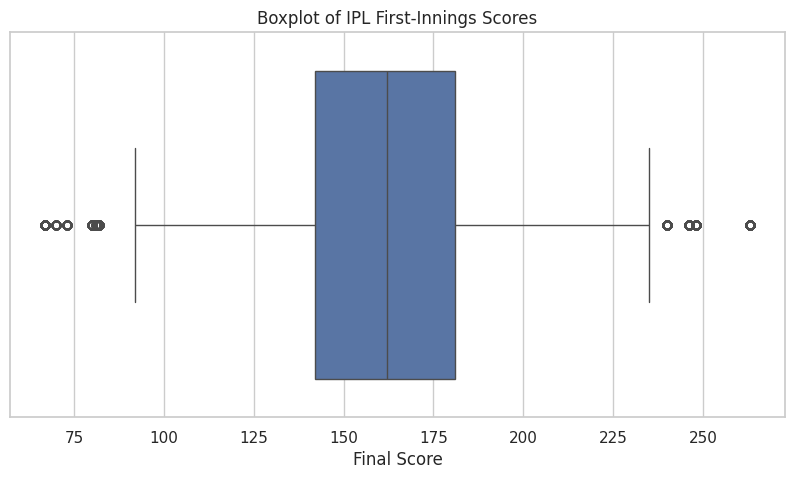

In [35]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="total"
)

plt.title("Boxplot of IPL First-Innings Scores")
plt.xlabel("Final Score")

plt.show()

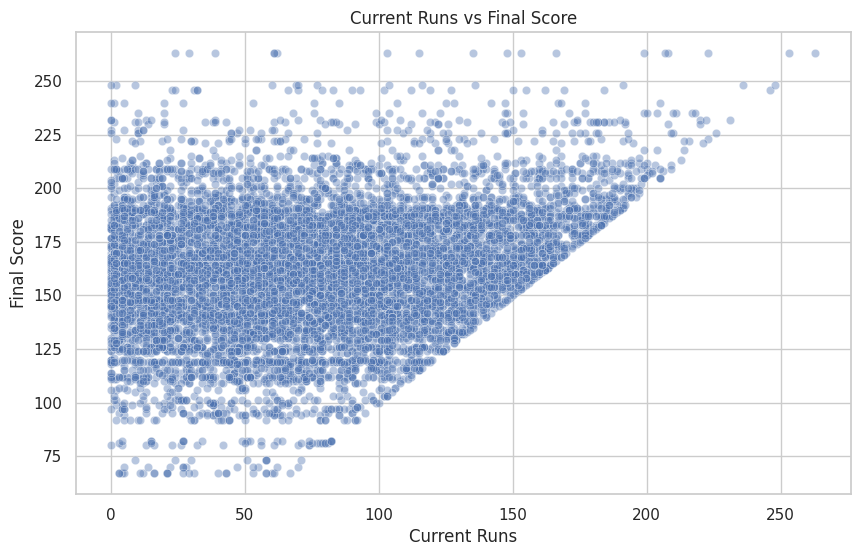

In [36]:
plt.figure(figsize=(10, 6))

sample_df = df.sample(
    min(10000, len(df)),
    random_state=42
)

sns.scatterplot(
    data=sample_df,
    x="runs",
    y="total",
    alpha=0.4
)

plt.title("Current Runs vs Final Score")
plt.xlabel("Current Runs")
plt.ylabel("Final Score")

plt.show()

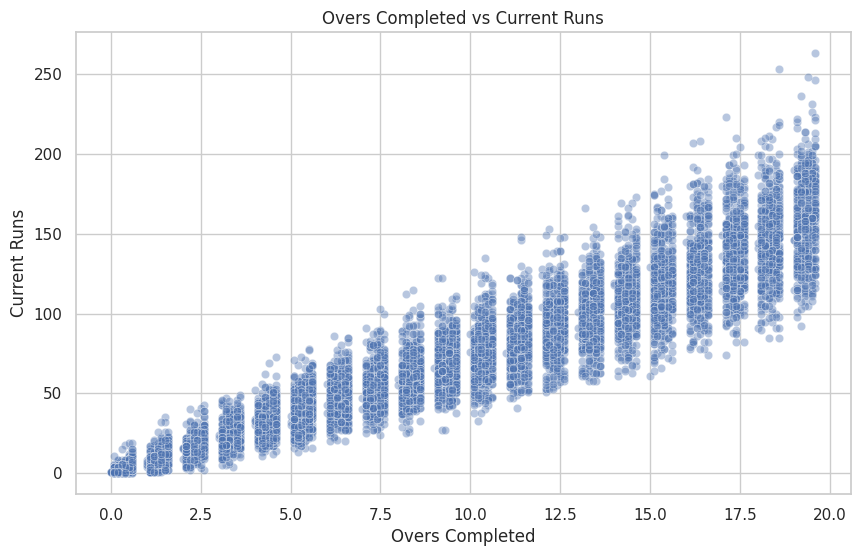

In [38]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=sample_df,
    x="overs",
    y="runs",
    alpha=0.4
)

plt.title("Overs Completed vs Current Runs")
plt.xlabel("Overs Completed")
plt.ylabel("Current Runs")

plt.show()

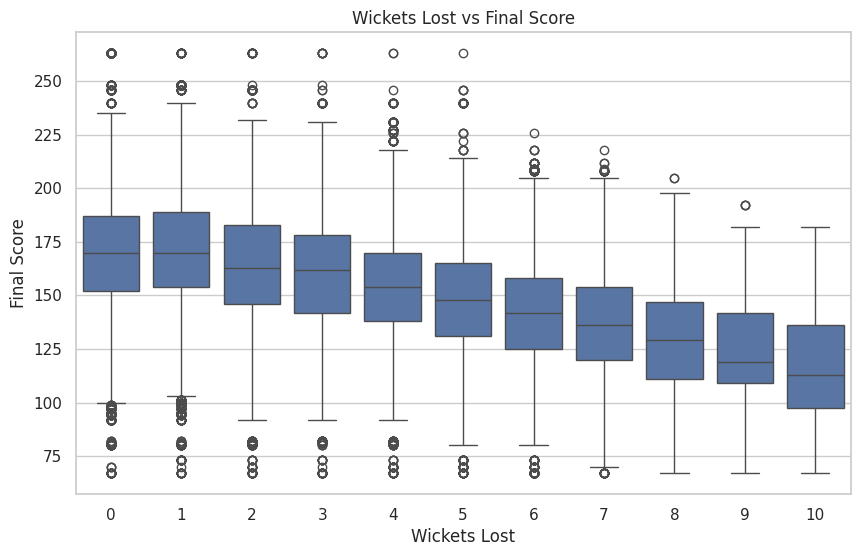

In [39]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="wickets",
    y="total"
)

plt.title("Wickets Lost vs Final Score")
plt.xlabel("Wickets Lost")
plt.ylabel("Final Score")

plt.show()

# **Data Preprocessing**

In [40]:
df["date"] = pd.to_datetime(
    df["date"],
    errors="coerce"
)

df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month

df.drop(
    columns=["date"],
    inplace=True
)

print("Date preprocessing completed.")

Date preprocessing completed.


In [41]:
# Current Run Rate
df["current_run_rate"] = np.where(
    df["overs"] > 0,
    df["runs"] / df["overs"],
    0
)

# Convert cricket overs into completed balls
df["balls_completed"] = (
    df["overs"].astype(int) * 6
    +
    ((df["overs"] % 1) * 10)
    .round()
    .astype(int)
)

# Balls remaining in a 20-over innings
df["balls_remaining"] = (
    120 - df["balls_completed"]
)

# Wickets remaining
df["wickets_remaining"] = (
    10 - df["wickets"]
)

# Simple projected score
df["projected_score"] = np.where(
    df["current_run_rate"] > 0,
    df["current_run_rate"] * 20,
    0
)

print("Feature engineering completed.")

Feature engineering completed.


In [42]:
engineered_features = [
    "current_run_rate",
    "balls_completed",
    "balls_remaining",
    "wickets_remaining",
    "projected_score"
]

df[engineered_features].head(10)

,current_run_rate,balls_completed,balls_remaining,wickets_remaining,projected_score
0,10.000000,1,119,10,200.000000
1,5.000000,2,118,10,100.000000
2,10.000000,2,118,10,200.000000
3,6.666667,3,117,10,133.333333
4,5.000000,4,116,10,100.000000
5,4.000000,5,115,10,80.000000
6,5.000000,6,114,10,100.000000
7,2.727273,7,113,10,54.545455
8,5.833333,8,112,10,116.666667
9,8.461538,9,111,10,169.230769


# **Feature and Target Selection**

In [43]:
target = "total"

features = [
    "venue",
    "batting_team",
    "bowling_team",

    "runs",
    "wickets",
    "overs",

    "runs_last_5",
    "wickets_last_5",

    "striker",
    "non-striker",

    "year",
    "month",

    "current_run_rate",
    "balls_completed",
    "balls_remaining",
    "wickets_remaining",
    "projected_score"
]

X = df[features]
y = df[target]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (76014, 17)
Target shape: (76014,)


In [44]:
feature_info = pd.DataFrame({
    "Feature": X.columns,
    "Data Type": X.dtypes.values,
    "Missing Values": X.isnull().sum().values
})

feature_info

,Feature,Data Type,Missing Values
0,venue,object,0
1,batting_team,object,0
2,bowling_team,object,0
3,runs,int64,0
4,wickets,int64,0
5,overs,float64,0
6,runs_last_5,int64,0
7,wickets_last_5,int64,0
8,striker,int64,0
9,non-striker,int64,0


# **Train-Test Split**

In [45]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 60811
Testing samples: 15203


# **Define Preprocessing Pipeline**

In [46]:
categorical_features = [
    "venue",
    "batting_team",
    "bowling_team"
]

print("Categorical features:")

for feature in categorical_features:
    print("-", feature)

Categorical features:
- venue
- batting_team
- bowling_team


In [47]:
numerical_features = [
    "runs",
    "wickets",
    "overs",
    "runs_last_5",
    "wickets_last_5",
    "striker",
    "non-striker",
    "year",
    "month",
    "current_run_rate",
    "balls_completed",
    "balls_remaining",
    "wickets_remaining",
    "projected_score"
]

print("Numerical features:")

for feature in numerical_features:
    print("-", feature)

Numerical features:
- runs
- wickets
- overs
- runs_last_5
- wickets_last_5
- striker
- non-striker
- year
- month
- current_run_rate
- balls_completed
- balls_remaining
- wickets_remaining
- projected_score


In [48]:
numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

print(
    "Numerical preprocessing pipeline created."
)

Numerical preprocessing pipeline created.


In [49]:
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

print(
    "Categorical preprocessing pipeline created."
)

Categorical preprocessing pipeline created.


In [50]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_transformer,
            numerical_features
        ),
        (
            "categorical",
            categorical_transformer,
            categorical_features
        )
    ]
)

print(
    "Complete preprocessing pipeline created."
)

Complete preprocessing pipeline created.


# **Define Machine Learning Models**

In [51]:
models = {

    "Ridge Regression": Ridge(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    ),

    "XGBoost": XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )
}

print("Candidate models:")

for model_name in models:
    print("-", model_name)

Candidate models:
- Ridge Regression
- Decision Tree
- Random Forest
- Extra Trees
- Gradient Boosting
- XGBoost


# **Model Training**

In [52]:
trained_models = {}

for name, model in models.items():

    print(
        f"Training {name}..."
    )

    pipeline = Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor
            ),
            (
                "model",
                model
            )
        ]
    )

    pipeline.fit(
        X_train,
        y_train
    )

    trained_models[name] = pipeline

print(
    "\nAll models trained successfully."
)

Training Ridge Regression...
Training Decision Tree...
Training Random Forest...
Training Extra Trees...
Training Gradient Boosting...
Training XGBoost...

All models trained successfully.


# **Model Evaluation**

In [53]:
model_results = []

for name, model in trained_models.items():

    predictions = model.predict(
        X_test
    )

    mae = mean_absolute_error(
        y_test,
        predictions
    )

    mse = mean_squared_error(
        y_test,
        predictions
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_test,
        predictions
    )

    model_results.append({

        "Model": name,

        "MAE": mae,

        "MSE": mse,

        "RMSE": rmse,

        "R2 Score": r2
    })


results_df = pd.DataFrame(
    model_results
)

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

results_df

,Model,MAE,MSE,RMSE,R2 Score
0,Extra Trees,0.958291,7.954129,2.820306,0.990570
1,Random Forest,2.443838,31.245722,5.589787,0.962957
2,Decision Tree,1.953628,77.198382,8.786261,0.908478
3,XGBoost,6.160320,78.641174,8.867986,0.906767
4,Gradient Boosting,13.086954,319.566458,17.876422,0.621139
5,Ridge Regression,14.386179,373.533294,19.327009,0.557158


In [54]:
results_df["Rank"] = (
    results_df["RMSE"]
    .rank(
        method="min",
        ascending=True
    )
    .astype(int)
)

results_df = results_df.sort_values(
    by="Rank"
).reset_index(drop=True)

results_df

,Model,MAE,MSE,RMSE,R2 Score,Rank
0,Extra Trees,0.958291,7.954129,2.820306,0.990570,1
1,Random Forest,2.443838,31.245722,5.589787,0.962957,2
2,Decision Tree,1.953628,77.198382,8.786261,0.908478,3
3,XGBoost,6.160320,78.641174,8.867986,0.906767,4
4,Gradient Boosting,13.086954,319.566458,17.876422,0.621139,5
5,Ridge Regression,14.386179,373.533294,19.327009,0.557158,6


# **Visualize Model Performance**

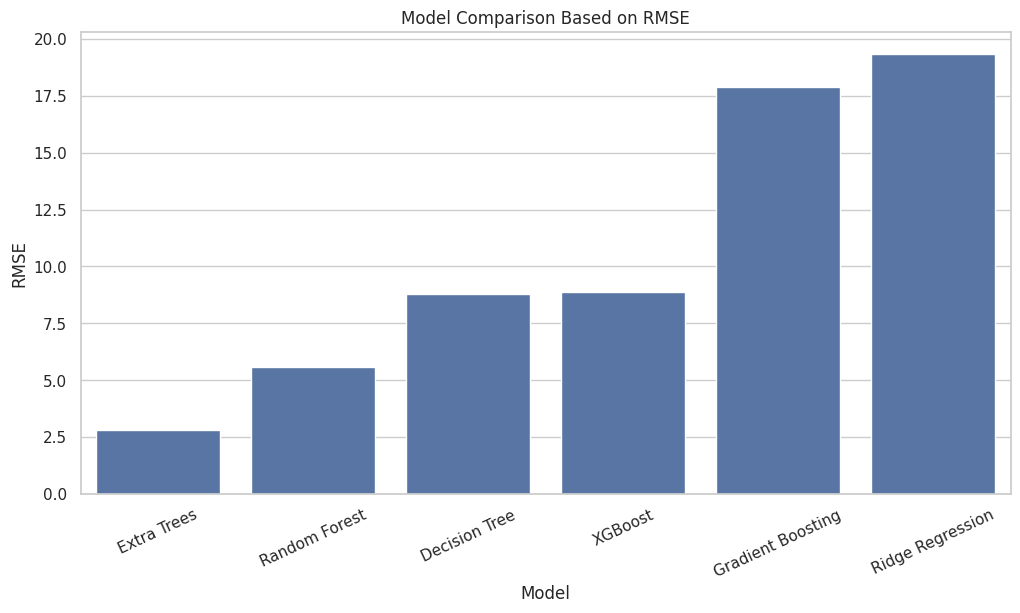

In [55]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE"
)

plt.title(
    "Model Comparison Based on RMSE"
)

plt.xlabel("Model")
plt.ylabel("RMSE")

plt.xticks(rotation=25)

plt.show()

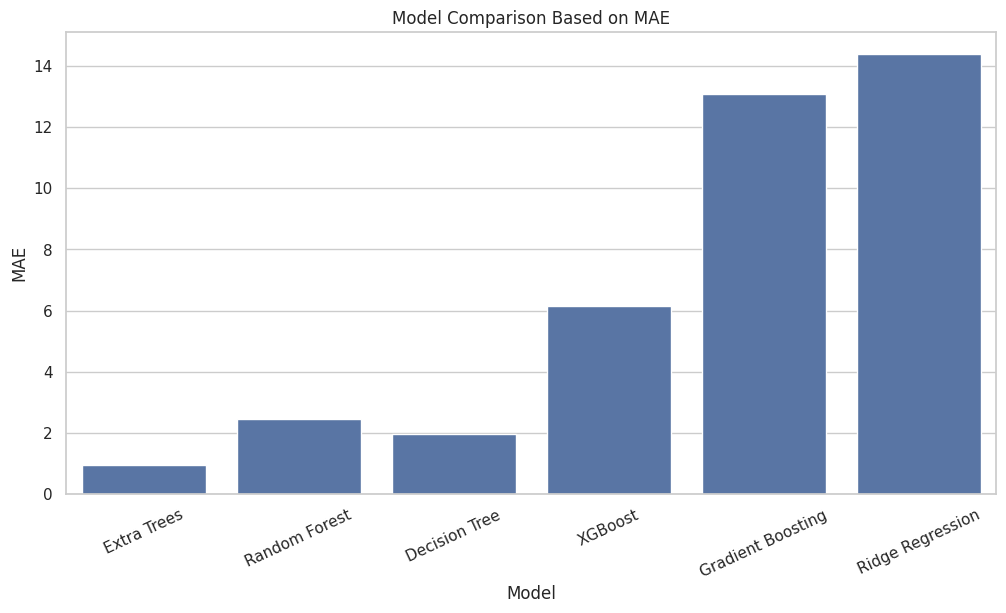

In [56]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="MAE"
)

plt.title(
    "Model Comparison Based on MAE"
)

plt.xlabel("Model")
plt.ylabel("MAE")

plt.xticks(rotation=25)

plt.show()

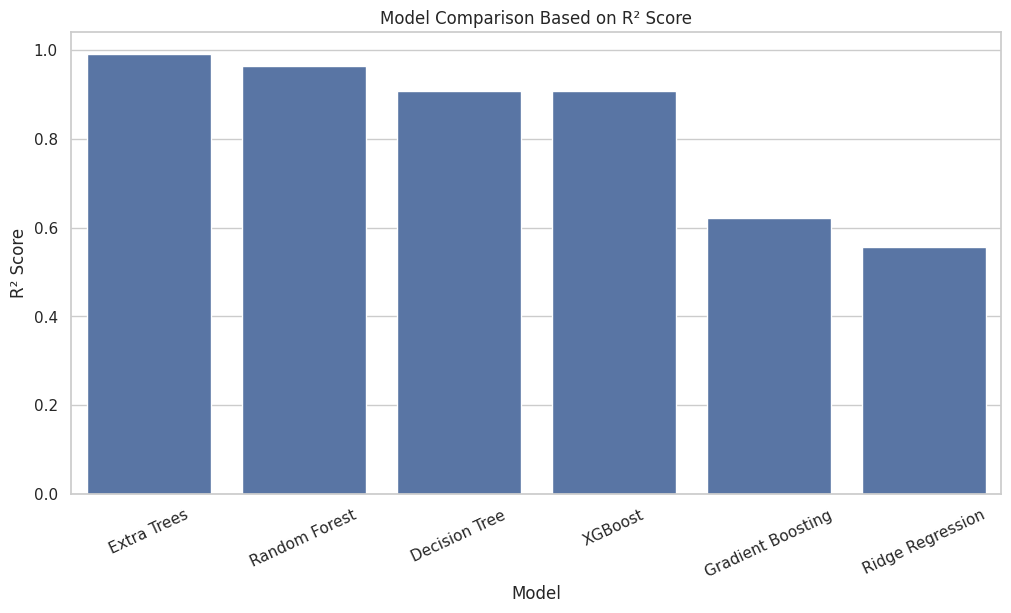

In [57]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="R2 Score"
)

plt.title(
    "Model Comparison Based on R² Score"
)

plt.xlabel("Model")
plt.ylabel("R² Score")

plt.xticks(rotation=25)

plt.show()

# **Automatic Best Model Selection**

In [58]:
best_model_name = results_df.loc[
    0,
    "Model"
]

best_model = trained_models[
    best_model_name
]

print("=" * 60)
print("BEST MODEL SELECTED AUTOMATICALLY")
print("=" * 60)

print(
    f"Best Model : {best_model_name}"
)

print(
    f"MAE        : "
    f"{results_df.loc[0, 'MAE']:.2f}"
)

print(
    f"RMSE       : "
    f"{results_df.loc[0, 'RMSE']:.2f}"
)

print(
    f"R² Score   : "
    f"{results_df.loc[0, 'R2 Score']:.4f}"
)

print("\nSelection criterion:")
print("Lowest RMSE")

BEST MODEL SELECTED AUTOMATICALLY
Best Model : Extra Trees
MAE        : 0.96
RMSE       : 2.82
R² Score   : 0.9906

Selection criterion:
Lowest RMSE


In [59]:
best_estimator = best_model.named_steps[
    "model"
]

print("Selected model:")
print(best_estimator)

Selected model:
ExtraTreesRegressor(n_jobs=-1, random_state=42)


# **Final Best Model Evaluation**

In [60]:
final_predictions = best_model.predict(
    X_test
)

print(
    "Final predictions generated successfully."
)

print(
    "Number of predictions:",
    len(final_predictions)
)

Final predictions generated successfully.
Number of predictions: 15203


In [61]:
final_mae = mean_absolute_error(
    y_test,
    final_predictions
)

final_mse = mean_squared_error(
    y_test,
    final_predictions
)

final_rmse = np.sqrt(
    final_mse
)

final_r2 = r2_score(
    y_test,
    final_predictions
)

print("=" * 60)
print("FINAL MODEL EVALUATION")
print("=" * 60)

print(
    f"Best Model : {best_model_name}"
)

print(
    f"MAE        : {final_mae:.2f} runs"
)

print(
    f"MSE        : {final_mse:.2f}"
)

print(
    f"RMSE       : {final_rmse:.2f} runs"
)

print(
    f"R² Score   : {final_r2:.4f}"
)

FINAL MODEL EVALUATION
Best Model : Extra Trees
MAE        : 0.96 runs
MSE        : 7.95
RMSE       : 2.82 runs
R² Score   : 0.9906


# **Model Performance Visualization**

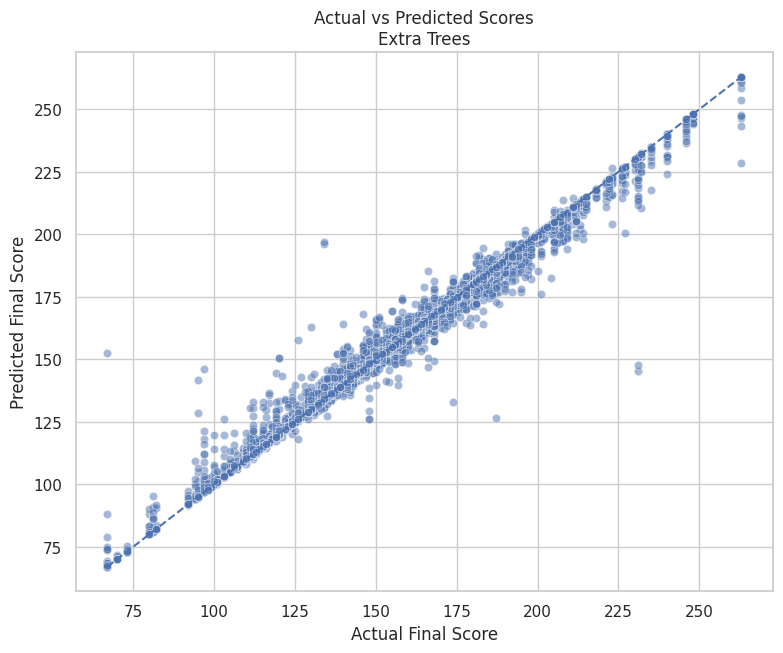

In [62]:
plt.figure(figsize=(9, 7))

sns.scatterplot(
    x=y_test,
    y=final_predictions,
    alpha=0.5
)

min_value = min(
    y_test.min(),
    final_predictions.min()
)

max_value = max(
    y_test.max(),
    final_predictions.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel(
    "Actual Final Score"
)

plt.ylabel(
    "Predicted Final Score"
)

plt.title(
    f"Actual vs Predicted Scores\n"
    f"{best_model_name}"
)

plt.show()

In [63]:
residuals = (
    y_test -
    final_predictions
)

residual_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": final_predictions,
    "Residual": residuals.values
})

residual_df.head(10)

,Actual,Predicted,Residual
0,134,134.00,0.00
1,195,195.14,-0.14
2,183,180.91,2.09
3,183,180.23,2.77
4,193,189.27,3.73
5,136,136.00,0.00
6,186,185.78,0.22
7,176,174.93,1.07
8,148,148.21,-0.21
9,135,135.00,0.00


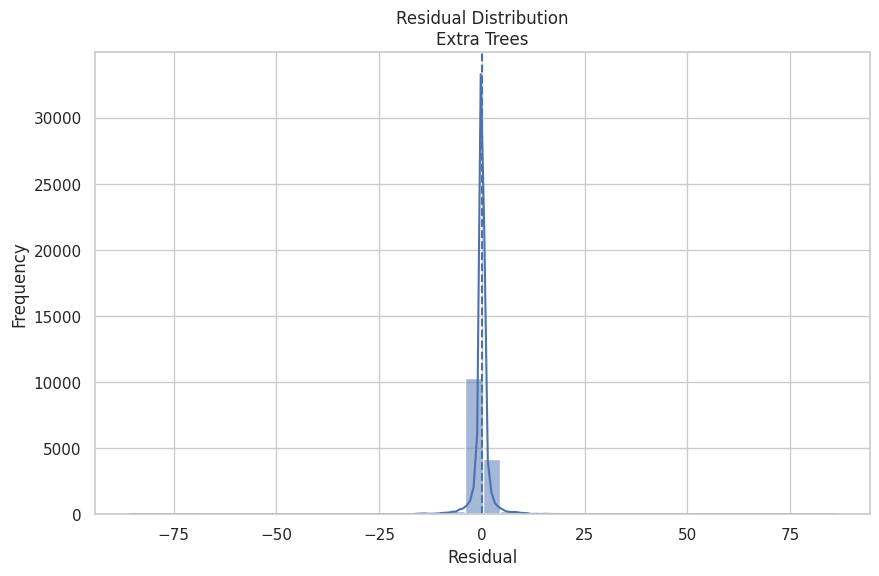

In [64]:
plt.figure(figsize=(10, 6))

sns.histplot(
    residuals,
    bins=40,
    kde=True
)

plt.axvline(
    0,
    linestyle="--"
)

plt.title(
    f"Residual Distribution\n"
    f"{best_model_name}"
)

plt.xlabel("Residual")
plt.ylabel("Frequency")

plt.show()

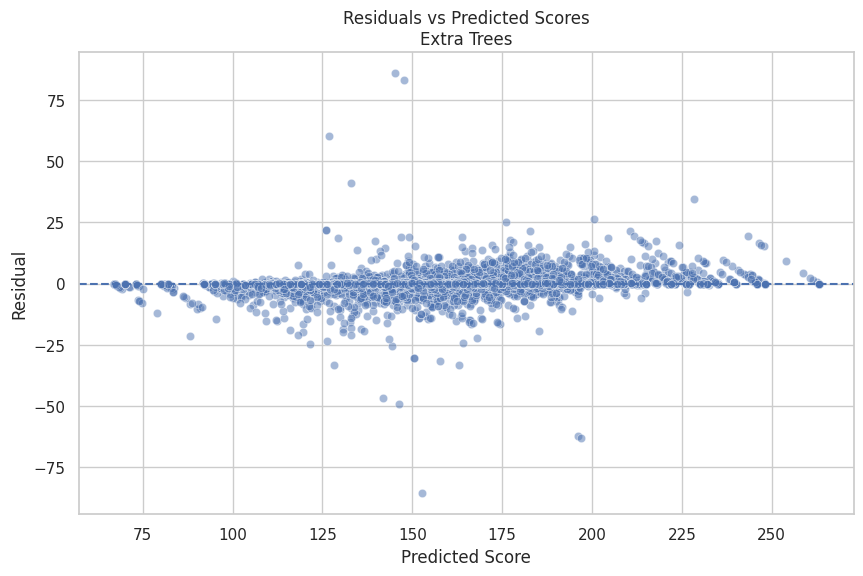

In [65]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=final_predictions,
    y=residuals,
    alpha=0.5
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Predicted Score"
)

plt.ylabel(
    "Residual"
)

plt.title(
    f"Residuals vs Predicted Scores\n"
    f"{best_model_name}"
)

plt.show()

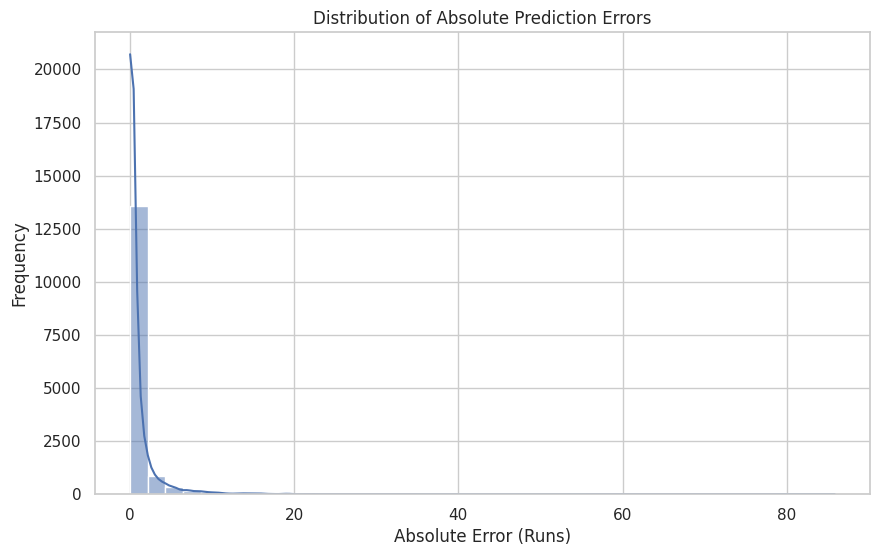

In [66]:
absolute_errors = np.abs(
    y_test.values -
    final_predictions
)

plt.figure(figsize=(10, 6))

sns.histplot(
    absolute_errors,
    bins=40,
    kde=True
)

plt.title(
    "Distribution of Absolute Prediction Errors"
)

plt.xlabel(
    "Absolute Error (Runs)"
)

plt.ylabel(
    "Frequency"
)

plt.show()

# **Feature Importance**

In [67]:
final_preprocessor = (
    best_model.named_steps[
        "preprocessor"
    ]
)

final_estimator = (
    best_model.named_steps[
        "model"
    ]
)

feature_names = (
    final_preprocessor
    .get_feature_names_out()
)

print(
    "Number of processed features:",
    len(feature_names)
)

Number of processed features: 77


In [68]:
if hasattr(
    final_estimator,
    "feature_importances_"
):

    importance_values = (
        final_estimator
        .feature_importances_
    )

elif hasattr(
    final_estimator,
    "coef_"
):

    importance_values = np.abs(
        final_estimator.coef_
    )

else:

    importance_values = None


if importance_values is not None:

    feature_importance_df = pd.DataFrame({

        "Feature": feature_names,

        "Importance": importance_values

    }).sort_values(
        by="Importance",
        ascending=False
    )

    feature_importance_df.head(20)

else:

    print(
        "Native feature importance is "
        "not available for this model."
    )

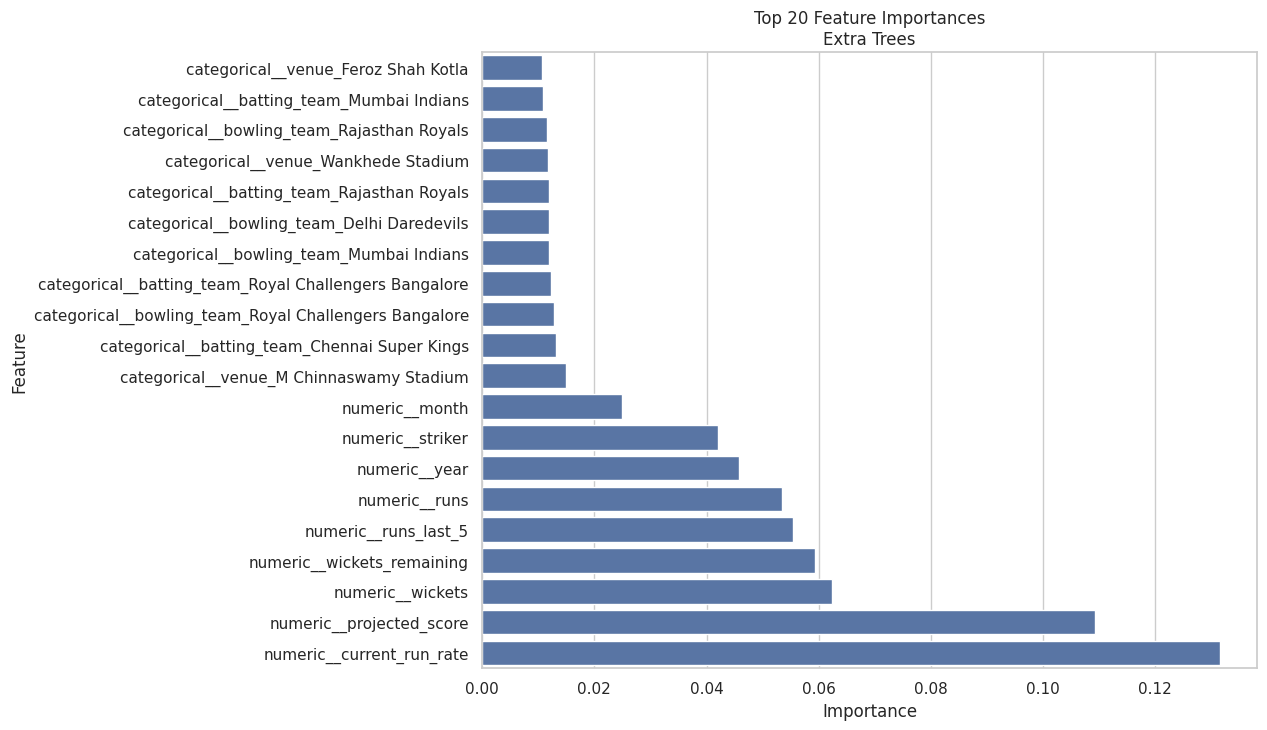

In [69]:
if importance_values is not None:

    top_features = (
        feature_importance_df
        .head(20)
        .sort_values(
            by="Importance"
        )
    )

    plt.figure(
        figsize=(10, 8)
    )

    sns.barplot(
        data=top_features,
        x="Importance",
        y="Feature"
    )

    plt.title(
        f"Top 20 Feature Importances\n"
        f"{best_model_name}"
    )

    plt.xlabel("Importance")
    plt.ylabel("Feature")

    plt.show()

# **Save the Best Model**

In [76]:
model_filename = (
    "ipl_first_innings_best_model.pkl"
)

joblib.dump(
    best_model,
    model_filename
)

print(
    f"Best model saved as: "
    f"{model_filename}"
)

Best model saved as: ipl_first_innings_best_model.pkl


# **Test the Model on New Match Situation**

In [77]:
new_innings = pd.DataFrame({

    "venue": [
        "M Chinnaswamy Stadium"
    ],

    "batting_team": [
        "Royal Challengers Bangalore"
    ],

    "bowling_team": [
        "Mumbai Indians"
    ],

    "runs": [
        85
    ],

    "wickets": [
        2
    ],

    "overs": [
        10.0
    ],

    "runs_last_5": [
        48
    ],

    "wickets_last_5": [
        1
    ],

    "striker": [
        1
    ],

    "non-striker": [
        2
    ],

    "year": [
        2026
    ],

    "month": [
        4
    ],

    "current_run_rate": [
        8.5
    ],

    "balls_completed": [
        60
    ],

    "balls_remaining": [
        60
    ],

    "wickets_remaining": [
        8
    ],

    "projected_score": [
        170
    ]
})

new_innings

,venue,batting_team,bowling_team,runs,wickets,overs,runs_last_5,wickets_last_5,striker,non-striker,year,month,current_run_rate,balls_completed,balls_remaining,wickets_remaining,projected_score
0,M Chinnaswamy Stadium,Royal Challengers Bangalore,Mumbai Indians,85,2,10.0,48,1,1,2,2026,4,8.5,60,60,8,170


In [78]:
predicted_score = best_model.predict(
    new_innings
)

print("=" * 50)

print(
    f"Selected Model: "
    f"{best_model_name}"
)

print(
    f"Predicted Final Score: "
    f"{predicted_score[0]:.0f}"
)

print("=" * 50)

Selected Model: Extra Trees
Predicted Final Score: 169


# **Final Results Summary**

In [79]:
final_summary = pd.DataFrame({

    "Best Model": [
        best_model_name
    ],

    "MAE": [
        final_mae
    ],

    "MSE": [
        final_mse
    ],

    "RMSE": [
        final_rmse
    ],

    "R2 Score": [
        final_r2
    ]
})

final_summary

,Best Model,MAE,MSE,RMSE,R2 Score
0,Extra Trees,0.958291,7.954129,2.820306,0.99057
